### description    :Estimate the expected pairwise LD among adjacent markers in genomic windows
### author         :RoshanAbeyratne & HariChhetri
### date           :20022025

In [2]:
rm(list=ls())
library(tidyverse)
library(ggplot2)

In [3]:
# change these variables as needed
wdir = "/lustre/orion/syb111/proj-shared/Personal/abeyratnecr/switchgrass/sub_proj/snp2geneLD"
window_list_fn = paste0(wdir, "/pw_ld/1000000_500000.bed") # filename of the bed file with genomic intervals for LD estimation
setwd(wdir)

In [4]:
# Input window list
windows <- read.table(window_list_fn, header=F)
colnames(windows) <- c('Chr', 'Start', 'End')
dim(windows)
str(windows)

[1] 2207    3

'data.frame':	2207 obs. of  3 variables:
 $ Chr  : chr  "Chr01K" "Chr01K" "Chr01K" "Chr01K" ...
 $ Start: int  0 500000 1000000 1500000 2000000 2500000 3000000 3500000 4000000 4500000 ...
 $ End  : int  1000000 1500000 2000000 2500000 3000000 3500000 4000000 4500000 5000000 5500000 ...


In [33]:
# Estimate average pairrwise LD in genomic windows (This codeblock may need a bit of time to run)
chr_names = windows %>% pull(Chr) %>% unique()

# avg_ld <- NULL
# missing_files <- NULL
# missing_iterations <- NULL

for (i in 1:nrow(windows)) {
    filename <- paste0(wdir, '/gw_ld/', windows$Chr[i], '_', windows$Start[i], '_', windows$End[i], '.ld')
    if (file.exists(filename)) {
        pwld <- read.table(filename, header=TRUE)      
        avg_ld<- rbind(avg_ld, cbind(Chr=windows$Chr[i],
                                     Start=windows$Start[i],
                                     End=windows$End[i],
                                     Avg_ld=mean(pwld$R2)))
    } else {
        missing_files <- c(missing_files, filename)
        missing_iterations <- c(missing_iterations, i)
    }
}

avg_ld <- avg_ld %>% as.data.frame()

dim(avg_ld)
head(avg_ld)
tail(avg_ld)

[1] 2204    4

,Chr,Start,End,Avg_ld
,<chr>,<chr>,<chr>,<chr>
1,Chr01K,0,1000000,0.0550128981907731
2,Chr01K,500000,1500000,0.0568859699733561
3,Chr01K,1000000,2000000,0.0580233195997375
4,Chr01K,1500000,2500000,0.0556508478554714
5,Chr01K,2000000,3000000,0.057975330138045
6,Chr01K,2500000,3500000,0.0631150748335462


,Chr,Start,End,Avg_ld
,<chr>,<chr>,<chr>,<chr>
2199,Chr09N,80500000,81500000,0.0554404651544266
2200,Chr09N,81000000,82000000,0.0547845070182028
2201,Chr09N,81500000,82500000,0.0557669142337607
2202,Chr09N,82000000,83000000,0.0634237915156375
2203,Chr09N,82500000,83095581,0.0674230586171416
2204,Chr09N,83000000,83095581,0.0640197611919809


In [35]:
# Are there any missing files for the genomic interval LD estimation?
missing_iterations %>% length()
missing_iterations

# NOTE: At this point check if there are missing LD estimates for genomic windows. 
# Possible reasons for missing iterations could be failure of some iterations in the MPI script 2_*.mpi.sh

[1] 2

[1]  629 1700

In [36]:
chrom_list <- windows %>% pull(Chr) %>% unique() %>% sort()
chrom_list

[1] "Chr01K" "Chr01N" "Chr02K" "Chr02N" "Chr03K" "Chr03N" "Chr04K" "Chr04N"
 [9] "Chr05K" "Chr05N" "Chr06K" "Chr06N" "Chr07K" "Chr07N" "Chr08K" "Chr08N"
[17] "Chr09K" "Chr09N"

`geom_smooth()` using formula = 'y ~ x'


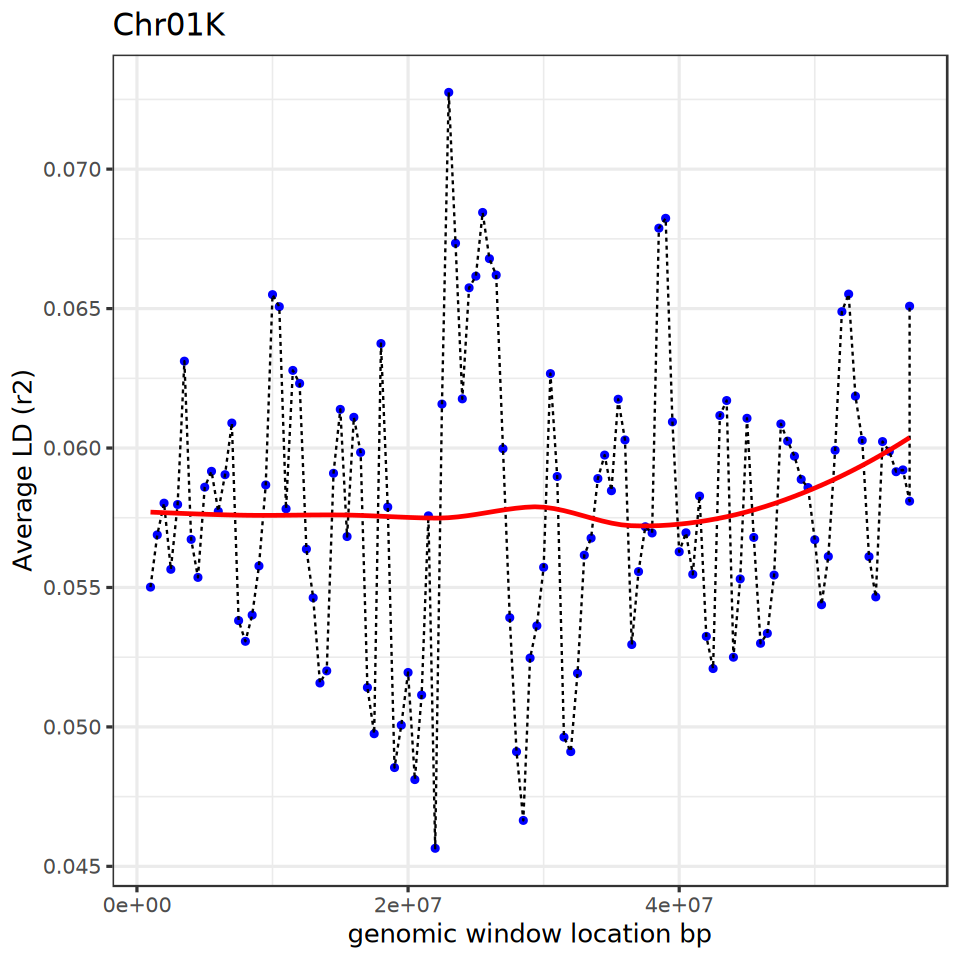

In [37]:
# For single chromosome plots
options(repr.plot.width=8, repr.plot.height=8)
chrom = chrom_list[1] # Chnage the idx to change the chromosome
avg_ld %>% as.data.frame() %>%
mutate(Avg_ld=as.numeric(Avg_ld)) %>% 
mutate(End=as.numeric(End)) %>% filter(Chr == chrom) %>%
ggplot(aes(x = End, y = Avg_ld)) +
geom_point(color = "blue") + 
geom_line(color = "black", linetype = "dashed") + 
geom_smooth(method = "loess", color = "red", se = FALSE) +
labs(x = "genomic window location bp", y = "Average LD (r2)", title = chrom) +
theme_minimal() + 
theme_bw(base_size=15)

`geom_smooth()` using formula = 'y ~ x'


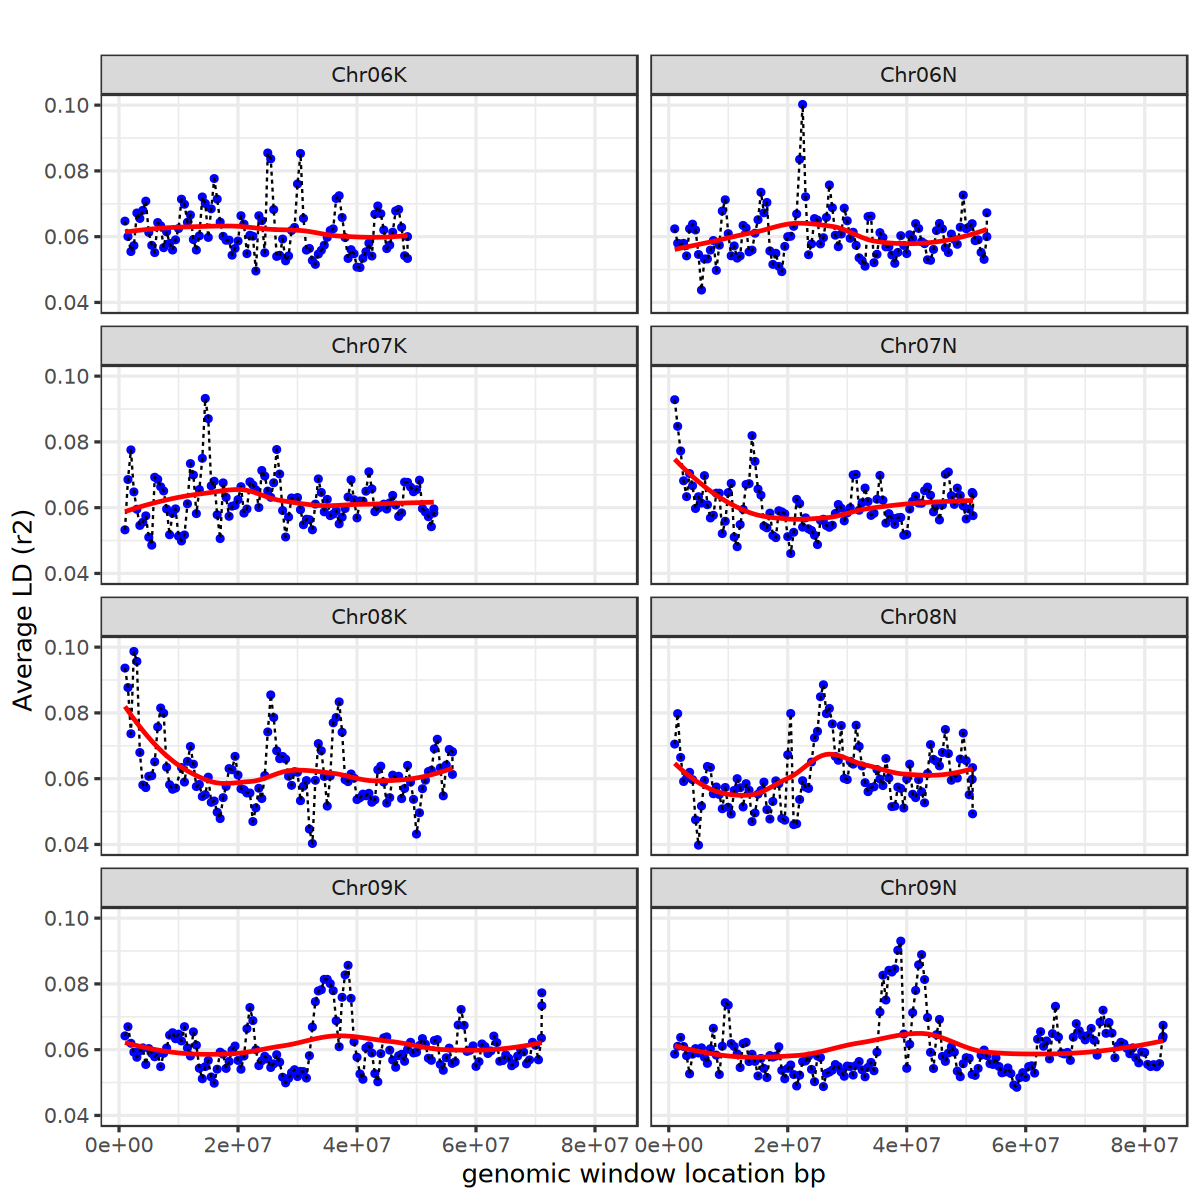

In [38]:
# For multiple chromosome plots
options(repr.plot.width=10, repr.plot.height=10)
chroms = chrom_list[11:18] # Chnage the idx to change the chromosomes to plot
avg_ld %>% as.data.frame() %>%
mutate(Avg_ld=as.numeric(Avg_ld)) %>% 
mutate(End=as.numeric(End)) %>% filter(Chr %in% chroms) %>%
ggplot(aes(x = End, y = Avg_ld)) +
geom_point(color = "blue") + 
geom_line(color = "black", linetype = "dashed") + 
geom_smooth(method = "loess", color = "red", se = FALSE) +
labs(x = "genomic window location bp", y = "Average LD (r2)", title = '') +
theme_minimal() + 
theme_bw(base_size=15) +
facet_wrap(~Chr, ncol = 2)
# facet_grid(rows = vars(Chr))

In [39]:
for (chr in unique(avg_ld$Chr)) {
    
    p <- avg_ld %>% filter(Chr == chr) %>% mutate(Avg_ld=as.numeric(Avg_ld)) %>% mutate(End=as.numeric(End)) %>%
    ggplot(aes(x = End, y = Avg_ld)) +
    geom_point(color = "blue") + 
    geom_line(color = "black", linetype = "dashed") + 
    geom_smooth(method = "loess", color = "red", se = FALSE) +
    labs(x = "genomic window location bp", y = "Average LD (r2)", title = chr) +
    theme_minimal() + 
    theme_bw(base_size=15)
    
    ggsave(filename = paste0("./gw_ld/", chr, "_ld.pdf"), plot=p, width=10, height=8)

}

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


In [ ]:
# END